# 07｜单文件 PPO 完整训练：InvertedPendulum-v5

这本 Notebook 从零写出并跑通完整的连续动作 PPO 训练闭环。**不会导入本仓库 `src/` 下的任何实现**；模型、rollout、GAE、PPO 更新、训练、评估和画图都在这里。

运行方式：选择项目环境的 Python 内核，然后 **Restart Kernel and Run All Cells**。默认训练 200,000 个环境步，不录制视频。

训练成功的直观标准：倒立摆每回合最多 1000 步，最终确定性评估的平均回合长度接近 1000。强化学习仍有随机性；本 Notebook 固定 seed 以便复现。

## 1. 环境与超参数

依赖只有 `gymnasium[mujoco]`、`numpy`、`torch` 和 `matplotlib`。如果还没有安装，可在项目根目录运行：

```bash
uv pip install -e ".[notebook]"
```

这里默认使用 CPU。这个网络很小，MuJoCo 仿真也在 CPU；在 Mac 上使用 MPS 通常不会更快。

In [1]:
from __future__ import annotations

import math
import random
import time
from dataclasses import dataclass

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.distributions import Normal


@dataclass
class Config:
    env_id: str = "InvertedPendulum-v5"
    total_timesteps: int = 200_000
    rollout_steps: int = 2_048
    update_epochs: int = 10
    minibatch_size: int = 64
    gamma: float = 0.99
    gae_lambda: float = 0.95
    clip_coef: float = 0.2
    actor_lr: float = 3e-4
    critic_lr: float = 1e-3
    entropy_coef: float = 0.0
    value_coef: float = 0.5
    max_grad_norm: float = 0.5
    hidden_size: int = 64
    max_episode_steps: int = 1_000
    seed: int = 1
    device: str = "cpu"


cfg = Config()
device = torch.device(cfg.device)
random.seed(cfg.seed)
np.random.seed(cfg.seed)
torch.manual_seed(cfg.seed)
torch.set_num_threads(1)

env = gym.make(cfg.env_id, max_episode_steps=cfg.max_episode_steps)
env.action_space.seed(cfg.seed)
obs, _ = env.reset(seed=cfg.seed)

obs_dim = int(np.prod(env.observation_space.shape))
action_dim = int(np.prod(env.action_space.shape))
action_low = torch.as_tensor(env.action_space.low, dtype=torch.float32, device=device)
action_high = torch.as_tensor(env.action_space.high, dtype=torch.float32, device=device)

print("PyTorch:", torch.__version__)
print("Gymnasium:", gym.__version__)
print("observation:", env.observation_space, "-> obs_dim =", obs_dim)
print("action:", env.action_space, "-> action_dim =", action_dim)

PyTorch: 2.5.1+cpu
Gymnasium: 1.4.0
observation: Box(-inf, inf, (4,), float64) -> obs_dim = 4
action: Box(-3.0, 3.0, (1,), float32) -> action_dim = 1


## 2. Actor–Critic

- Actor 输出高斯分布的均值，`log_std` 是可训练参数。
- rollout 保存的是高斯分布采样出的 **raw action** 及其旧 `log_prob`；只有送入环境时才裁剪到动作边界。
- Critic 输出标量状态价值 $v(s)$。
- PPO 更新时评价同一批旧动作，不重新采样动作。

In [2]:
def orthogonal_init(layer: nn.Module, gain: float = math.sqrt(2.0)) -> nn.Module:
    if isinstance(layer, nn.Linear):
        nn.init.orthogonal_(layer.weight, gain)
        nn.init.constant_(layer.bias, 0.0)
    return layer


def make_mlp(input_dim: int, hidden_size: int, output_dim: int, output_gain: float):
    network = nn.Sequential(
        nn.Linear(input_dim, hidden_size), nn.Tanh(),
        nn.Linear(hidden_size, hidden_size), nn.Tanh(),
        nn.Linear(hidden_size, output_dim),
    )
    for layer in network[:-1]:
        orthogonal_init(layer)
    orthogonal_init(network[-1], output_gain)
    return network


class ActorCritic(nn.Module):
    def __init__(self, obs_dim: int, action_dim: int, hidden_size: int):
        super().__init__()
        self.actor_mean = make_mlp(obs_dim, hidden_size, action_dim, output_gain=0.01)
        self.log_std = nn.Parameter(torch.full((action_dim,), -0.5))
        self.critic = make_mlp(obs_dim, hidden_size, 1, output_gain=1.0)

    def distribution(self, observations: torch.Tensor) -> Normal:
        mean = self.actor_mean(observations)
        std = self.log_std.exp().expand_as(mean)
        return Normal(mean, std)

    def value(self, observations: torch.Tensor) -> torch.Tensor:
        return self.critic(observations).squeeze(-1)

    @staticmethod
    def joint_log_prob(distribution: Normal, actions: torch.Tensor) -> torch.Tensor:
        return distribution.log_prob(actions).sum(dim=-1)

    @torch.no_grad()
    def act(self, observations: torch.Tensor):
        distribution = self.distribution(observations)
        raw_actions = distribution.sample()
        log_probs = self.joint_log_prob(distribution, raw_actions)
        values = self.value(observations)
        return raw_actions, log_probs, values

    def evaluate_actions(self, observations: torch.Tensor, actions: torch.Tensor):
        distribution = self.distribution(observations)
        log_probs = self.joint_log_prob(distribution, actions)
        entropies = distribution.entropy().sum(dim=-1)
        values = self.value(observations)
        return log_probs, entropies, values

    def actor_parameters(self):
        yield from self.actor_mean.parameters()
        yield self.log_std

    def critic_parameters(self):
        yield from self.critic.parameters()


model = ActorCritic(obs_dim, action_dim, cfg.hidden_size).to(device)
actor_optimizer = torch.optim.Adam(model.actor_parameters(), lr=cfg.actor_lr, eps=1e-5)
critic_optimizer = torch.optim.Adam(model.critic_parameters(), lr=cfg.critic_lr, eps=1e-5)

print(model)
print("initial action std:", model.log_std.exp().detach().cpu().numpy())

ActorCritic(
  (actor_mean): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
  (critic): Sequential(
    (0): Linear(in_features=4, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
initial action std: [0.60653067]


## 3. GAE：区分终止与截断

对每个时刻 $t$：

$$\delta_t=r_{t+1}+\gamma(1-\mathrm{terminated}_t)v(s_{t+1})-v(s_t)$$

真正终止（`terminated=True`）时，MDP 已结束，所以不使用 $v(s_{t+1})$。时间上限截断（`truncated=True`）时，状态本身并非终止状态，仍保留 bootstrap。

但 GAE 递推不能跨过任何一次 reset。因此递推项同时在 `terminated` 和 `truncated` 处切断：

$$A_t=\delta_t+\gamma\lambda(1-\mathrm{done}_t)A_{t+1}$$

In [3]:
def compute_gae(rewards, values, next_values, terminated, truncated, gamma, gae_lambda):
    advantages = torch.zeros_like(rewards)
    last_gae = torch.zeros((), dtype=rewards.dtype, device=rewards.device)

    for t in reversed(range(rewards.shape[0])):
        # terminated: 不 bootstrap；truncated: 仍 bootstrap
        bootstrap_mask = 1.0 - terminated[t].float()
        # 两者都会 reset，所以 GAE 都不能跨过去
        recursion_mask = 1.0 - torch.logical_or(terminated[t], truncated[t]).float()
        delta = rewards[t] + gamma * bootstrap_mask * next_values[t] - values[t]
        last_gae = delta + gamma * gae_lambda * recursion_mask * last_gae
        advantages[t] = last_gae

    returns = advantages + values
    return advantages.detach(), returns.detach()


# 一个很小的边界检查：截断保留 next_value，但不会把下一回合的优势传回来
test_adv, _ = compute_gae(
    rewards=torch.tensor([1.0, 1.0]),
    values=torch.tensor([0.0, 0.0]),
    next_values=torch.tensor([10.0, 20.0]),
    terminated=torch.tensor([False, False]),
    truncated=torch.tensor([True, False]),
    gamma=0.9,
    gae_lambda=1.0,
)
assert torch.allclose(test_adv, torch.tensor([10.0, 19.0]))
print("GAE boundary check passed:", test_adv.tolist())

GAE boundary check passed: [10.0, 19.0]


## 4. 收集 rollout

每一步都保存 $(s_t,a_t,\log\pi_{\theta_{old}}(a_t|s_t),r_{t+1},v(s_t),v(s_{t+1}))$ 以及两个结束标志。环境 reset 之后的观测只用于下一次决策，不会被误当成上一个 episode 的 $s_{t+1}$。

In [4]:
@dataclass
class RolloutBatch:
    observations: torch.Tensor
    raw_actions: torch.Tensor
    old_log_probs: torch.Tensor
    advantages: torch.Tensor
    returns: torch.Tensor


episode_lengths = []
episode_returns = []
current_episode_length = 0
current_episode_return = 0.0
global_step = 0


def collect_rollout(observation: np.ndarray, steps: int):
    global current_episode_length, current_episode_return, global_step

    observations, raw_actions, old_log_probs = [], [], []
    rewards, values, next_values = [], [], []
    terminated_flags, truncated_flags = [], []

    for _ in range(steps):
        obs_tensor = torch.as_tensor(observation, dtype=torch.float32, device=device).unsqueeze(0)
        with torch.no_grad():
            raw_action, old_log_prob, value = model.act(obs_tensor)

        env_action = torch.clamp(raw_action[0], action_low, action_high)
        next_observation, reward, terminated, truncated, _ = env.step(env_action.cpu().numpy())

        # 注意：这里在 reset 之前计算 v(s_{t+1})
        next_obs_tensor = torch.as_tensor(next_observation, dtype=torch.float32, device=device).unsqueeze(0)
        with torch.no_grad():
            next_value = model.value(next_obs_tensor)[0]

        observations.append(obs_tensor[0])
        raw_actions.append(raw_action[0])
        old_log_probs.append(old_log_prob[0])
        rewards.append(float(reward))
        values.append(value[0])
        next_values.append(next_value)
        terminated_flags.append(bool(terminated))
        truncated_flags.append(bool(truncated))

        global_step += 1
        current_episode_length += 1
        current_episode_return += float(reward)

        if terminated or truncated:
            episode_lengths.append(current_episode_length)
            episode_returns.append(current_episode_return)
            current_episode_length = 0
            current_episode_return = 0.0
            observation, _ = env.reset()
        else:
            observation = next_observation

    rewards_t = torch.tensor(rewards, dtype=torch.float32, device=device)
    values_t = torch.stack(values)
    next_values_t = torch.stack(next_values)
    terminated_t = torch.tensor(terminated_flags, dtype=torch.bool, device=device)
    truncated_t = torch.tensor(truncated_flags, dtype=torch.bool, device=device)
    advantages, returns = compute_gae(
        rewards_t, values_t, next_values_t, terminated_t, truncated_t,
        cfg.gamma, cfg.gae_lambda,
    )

    batch = RolloutBatch(
        observations=torch.stack(observations),
        raw_actions=torch.stack(raw_actions),
        old_log_probs=torch.stack(old_log_probs),
        advantages=advantages,
        returns=returns,
    )
    return observation, batch

## 5. PPO-Clip 更新

同一批 rollout 数据会被重复使用多个 epoch。Actor 最小化负的 clipped surrogate objective；Critic 拟合 $\hat A_t+v(s_t)$。优势只在整批 rollout 上归一化一次。

In [5]:
def ppo_update(batch: RolloutBatch):
    advantages = (batch.advantages - batch.advantages.mean()) / (
        batch.advantages.std(unbiased=False) + 1e-8
    )
    batch_size = batch.observations.shape[0]
    history = {key: [] for key in [
        "actor_loss", "critic_loss", "entropy", "approx_kl", "clip_fraction"
    ]}

    for _ in range(cfg.update_epochs):
        indices = torch.randperm(batch_size, device=device)
        for start in range(0, batch_size, cfg.minibatch_size):
            mb = indices[start:start + cfg.minibatch_size]
            new_log_probs, entropies, predicted_values = model.evaluate_actions(
                batch.observations[mb], batch.raw_actions[mb]
            )

            log_ratio = new_log_probs - batch.old_log_probs[mb]
            ratio = torch.exp(log_ratio)
            unclipped_objective = ratio * advantages[mb]
            clipped_objective = torch.clamp(
                ratio, 1.0 - cfg.clip_coef, 1.0 + cfg.clip_coef
            ) * advantages[mb]
            actor_loss = -torch.minimum(unclipped_objective, clipped_objective).mean()
            actor_objective = actor_loss - cfg.entropy_coef * entropies.mean()

            critic_loss = 0.5 * ((predicted_values - batch.returns[mb]) ** 2).mean()

            actor_optimizer.zero_grad(set_to_none=True)
            actor_objective.backward()
            torch.nn.utils.clip_grad_norm_(list(model.actor_parameters()), cfg.max_grad_norm)
            actor_optimizer.step()

            critic_optimizer.zero_grad(set_to_none=True)
            (cfg.value_coef * critic_loss).backward()
            torch.nn.utils.clip_grad_norm_(list(model.critic_parameters()), cfg.max_grad_norm)
            critic_optimizer.step()

            with torch.no_grad():
                approx_kl = ((ratio - 1.0) - log_ratio).mean()
                clip_fraction = ((ratio - 1.0).abs() > cfg.clip_coef).float().mean()

            history["actor_loss"].append(float(actor_loss.detach()))
            history["critic_loss"].append(float(critic_loss.detach()))
            history["entropy"].append(float(entropies.mean().detach()))
            history["approx_kl"].append(float(approx_kl))
            history["clip_fraction"].append(float(clip_fraction))

    return {key: float(np.mean(values)) for key, values in history.items()}

## 6. 完整训练

下面这一个循环完成：rollout → GAE → 多 epoch PPO 更新 → 记录曲线。默认约 98 次更新。

In [6]:
training_metrics = []
start_time = time.perf_counter()
update_index = 0

while global_step < cfg.total_timesteps:
    steps_this_rollout = min(cfg.rollout_steps, cfg.total_timesteps - global_step)
    obs, batch = collect_rollout(obs, steps_this_rollout)
    metrics = ppo_update(batch)
    update_index += 1

    recent_length = float(np.mean(episode_lengths[-20:])) if episode_lengths else np.nan
    training_metrics.append({
        "step": global_step,
        "mean_last_20_length": recent_length,
        "action_std": float(model.log_std.exp().mean().detach().cpu()),
        **metrics,
    })

    if update_index == 1 or update_index % 10 == 0 or global_step == cfg.total_timesteps:
        print(
            f"update={update_index:>3d}  step={global_step:>6d}  "
            f"episodes={len(episode_lengths):>4d}  "
            f"last20_length={recent_length:>7.1f}  "
            f"KL={metrics['approx_kl']:.5f}"
        )

elapsed = time.perf_counter() - start_time
print()
print(f"Training finished in {elapsed:.1f} s ({global_step / elapsed:.0f} env steps/s).")

update=  1  step=  2048  episodes= 186  last20_length=   12.4  KL=0.01154
update= 10  step= 20480  episodes= 662  last20_length=  154.1  KL=0.00939
update= 20  step= 40960  episodes= 698  last20_length=  802.8  KL=0.00466
update= 30  step= 61440  episodes= 718  last20_length=  995.1  KL=0.00530
update= 40  step= 81920  episodes= 739  last20_length= 1000.0  KL=0.00306
update= 50  step=102400  episodes= 759  last20_length= 1000.0  KL=0.00399
update= 60  step=122880  episodes= 780  last20_length= 1000.0  KL=0.00323
update= 70  step=143360  episodes= 800  last20_length= 1000.0  KL=0.00714
update= 80  step=163840  episodes= 821  last20_length= 1000.0  KL=0.00894
update= 90  step=184320  episodes= 841  last20_length= 1000.0  KL=0.00748
update= 98  step=200000  episodes= 857  last20_length= 1000.0  KL=0.00765

Training finished in 122.8 s (1629 env steps/s).


## 7. 训练曲线

环境每一步奖励为 1，因此回合 return 与回合 length 相同。这里直接画回合长度：越接近 1000，策略维持直立的时间越长。右图用于检查 PPO 更新是否过猛。

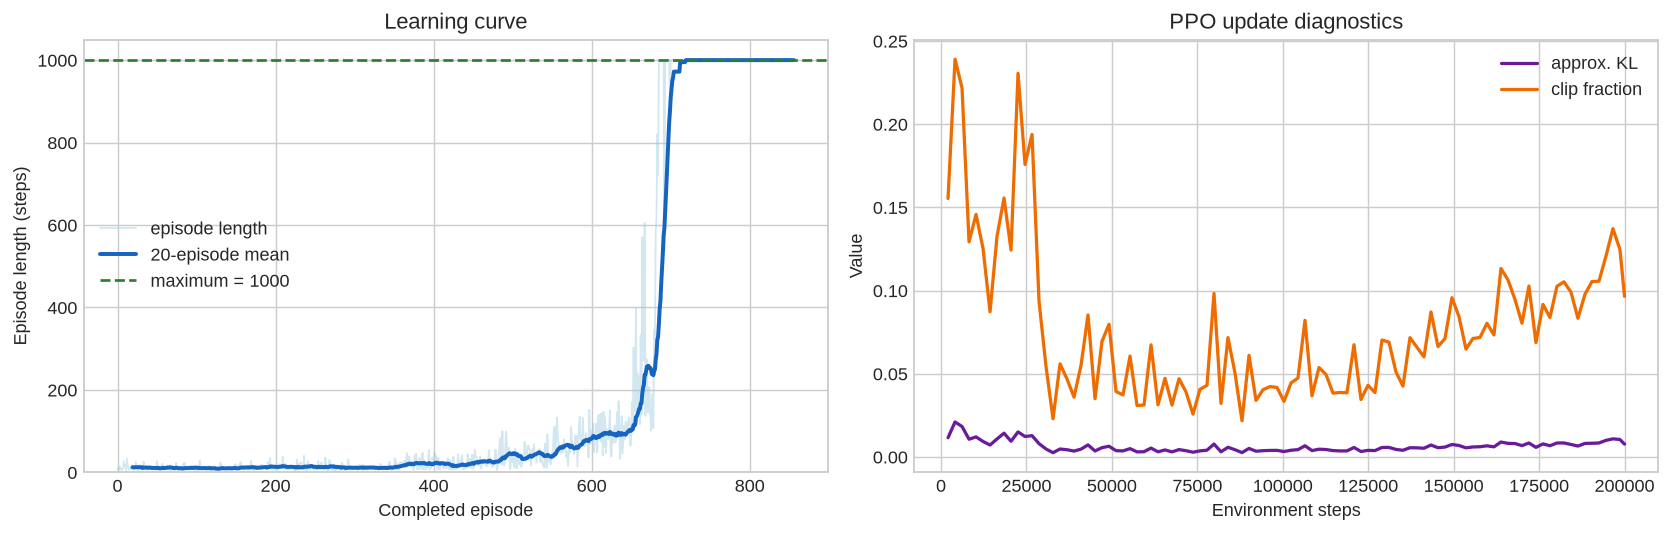

In [7]:
def moving_average(values, window=20):
    values = np.asarray(values, dtype=np.float64)
    if len(values) < window:
        return np.arange(len(values)), values
    kernel = np.ones(window) / window
    return np.arange(window - 1, len(values)), np.convolve(values, kernel, mode="valid")


episode_x, smoothed_lengths = moving_average(episode_lengths, window=20)
steps = np.array([row["step"] for row in training_metrics])
approx_kl = np.array([row["approx_kl"] for row in training_metrics])
clip_fraction = np.array([row["clip_fraction"] for row in training_metrics])

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].plot(episode_lengths, color="#9ecae1", alpha=0.45, linewidth=1, label="episode length")
axes[0].plot(episode_x, smoothed_lengths, color="#1565c0", linewidth=2.2, label="20-episode mean")
axes[0].axhline(cfg.max_episode_steps, color="#2e7d32", linestyle="--", linewidth=1.5, label="maximum = 1000")
axes[0].set(title="Learning curve", xlabel="Completed episode", ylabel="Episode length (steps)", ylim=(0, 1050))
axes[0].legend(frameon=False)

axes[1].plot(steps, approx_kl, color="#6a1b9a", linewidth=1.8, label="approx. KL")
axes[1].plot(steps, clip_fraction, color="#ef6c00", linewidth=1.8, label="clip fraction")
axes[1].set(title="PPO update diagnostics", xlabel="Environment steps", ylabel="Value")
axes[1].legend(frameon=False)

fig.tight_layout()
plt.show()

## 8. 最终确定性评估

训练时从高斯策略采样；评估时直接使用 Actor 的均值。这里运行 20 个 episode，不渲染、不录视频，只画最终长度分布。

evaluation lengths: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
mean evaluation length: 1000.0 / 1000
1000-step success rate: 100%
Training target reached: the learned policy keeps the pendulum upright reliably.


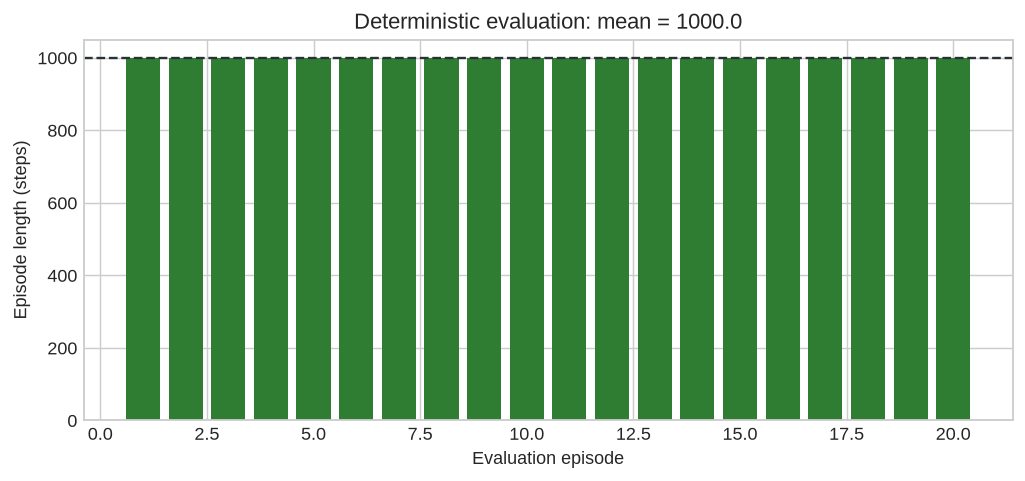

In [8]:
@torch.no_grad()
def evaluate_policy(episodes=20, seed=10_000):
    eval_env = gym.make(cfg.env_id, max_episode_steps=cfg.max_episode_steps)
    lengths = []

    for episode in range(episodes):
        eval_obs, _ = eval_env.reset(seed=seed + episode)
        episode_length = 0
        done = False
        while not done:
            obs_tensor = torch.as_tensor(eval_obs, dtype=torch.float32, device=device).unsqueeze(0)
            action = model.actor_mean(obs_tensor)[0]
            action = torch.clamp(action, action_low, action_high)
            eval_obs, _, terminated, truncated, _ = eval_env.step(action.cpu().numpy())
            episode_length += 1
            done = terminated or truncated
        lengths.append(episode_length)

    eval_env.close()
    return np.asarray(lengths)


evaluation_lengths = evaluate_policy(episodes=20)
mean_eval_length = float(evaluation_lengths.mean())
success_rate = float(np.mean(evaluation_lengths == cfg.max_episode_steps))

print("evaluation lengths:", evaluation_lengths.tolist())
print(f"mean evaluation length: {mean_eval_length:.1f} / {cfg.max_episode_steps}")
print(f"1000-step success rate: {success_rate:.0%}")

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = ["#2e7d32" if length == cfg.max_episode_steps else "#f9a825" for length in evaluation_lengths]
ax.bar(np.arange(1, len(evaluation_lengths) + 1), evaluation_lengths, color=colors)
ax.axhline(cfg.max_episode_steps, color="#263238", linestyle="--", linewidth=1.3)
ax.set(
    title=f"Deterministic evaluation: mean = {mean_eval_length:.1f}",
    xlabel="Evaluation episode",
    ylabel="Episode length (steps)",
    ylim=(0, 1050),
)
fig.tight_layout()
plt.show()

if mean_eval_length >= 950:
    print("Training target reached: the learned policy keeps the pendulum upright reliably.")
else:
    print("Training ran to completion, but this seed did not reach the target. Try another seed or more timesteps.")

env.close()

## 9. 从这本 Notebook 看完整数据流

1. 当前观测 $s_t$ 进入 Actor 和 Critic，得到动作分布与 $v(s_t)$。
2. 采样 $a_t$，保存旧 $\log\pi_{\theta_{old}}(a_t|s_t)$，裁剪后送入环境。
3. 环境返回 $r_{t+1},s_{t+1},\mathrm{terminated},\mathrm{truncated}$；在 reset 前计算 $v(s_{t+1})$。
4. 时间有序的 rollout 计算 GAE 与 Critic target。
5. 打乱 rollout，分 mini-batch 多次更新 Actor 和 Critic。
6. 重复以上过程，最后用确定性动作评估并画图。

这份文件有意保留教学实现的简洁性：单环境、未截断高斯（环境动作再裁剪）、无观测归一化、无学习率退火。迁移到更复杂的机器人任务时，再逐步引入并行环境、`tanh` squashed Gaussian、归一化和更完整的日志。